# 2. Preprocessing dan Pelabelan Data
**Kriteria 2:** Ekstraksi fitur dan pelabelan data

Pipeline preprocessing:
1. Lowercase (case folding)
2. Hapus noise (mention, hashtag, URL, HTML, angka, emoji, tanda baca)
3. Normalisasi slang/alay (500+ entri kamus)
4. Tokenisasi (NLTK word_tokenize)
5. Hapus stopword (Indonesian + English + custom domain)
6. Stemming (Sastrawi)

**Pelabelan:** Otomatis berdasarkan rating bintang
- 1-2 bintang → Negatif
- 3 bintang → Netral
- 4-5 bintang → Positif

In [41]:
# Imports
import pandas as pd
import numpy as np
import re
import string
import os
import warnings
import joblib
import nltk
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report,
                              confusion_matrix, ConfusionMatrixDisplay)
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (Input, Embedding, LSTM, Bidirectional,
                                      Dense, Dropout, Layer, SpatialDropout1D)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import tensorflow.keras.backend as K
from gensim.models import FastText
from wordcloud import WordCloud

nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
warnings.filterwarnings('ignore')

os.makedirs('models', exist_ok=True)
os.makedirs('data', exist_ok=True)

# Load raw data
df = pd.read_csv('data/raw_reviews.csv')
print(f"Loaded {len(df)} reviews")
print(f"Total NaN values: {df.isna().sum().sum()}")
df.head()

Loaded 9077 reviews
Total NaN values: 0


,reviewId,content,score,at,thumbsUpCount
0,d08530dd-6412-48bd-99df-80e53bf9c9d2,mantap. perbanyak hadianya jago,4,2026-03-27 16:25:47,0
1,aba11d3a-1739-4ed1-bee0-093ac3bcc5ca,"Di tambah feature (Kantong) Syariah kak, (dengan im...",5,2026-03-27 11:08:15,4
2,159e687d-7d07-4853-af8d-863a2d1578a2,transaksi cepat,5,2026-03-27 10:07:21,0
3,274985ea-be71-4f0f-b1f7-4dc82d8658cb,food,5,2026-03-27 09:13:40,0
4,a6fcbe02-9084-4f0d-96b5-9743a54bbe3b,"akun saya dikunci secara tiba-tiba, tidak ada penje...",1,2026-03-27 08:53:57,0


In [42]:
# Cell 2: Labeling by star rating
def assign_label(score):
    if score <= 2:
        return 'Negatif'
    elif score == 3:
        return 'Netral'
    else:
        return 'Positif'

df['label'] = df['score'].apply(assign_label)
print("Label distribution:")
print(df['label'].value_counts())
print(f"\nPercentages:")
print(df['label'].value_counts(normalize=True).round(3) * 100)

Label distribution:
label
Positif    6140
Negatif    2617
Netral      320
Name: count, dtype: int64

Percentages:
label
Positif    67.6
Negatif    28.8
Netral      3.5
Name: proportion, dtype: float64


In [43]:
# Cell 3: Slang/alay normalization dictionary (500+ entries)
# Merged from multiple Indonesian slang/alay sources
slang_dict = {
    # === Common abbreviations ===
    "gk": "tidak", "ga": "tidak", "gak": "tidak", "ngga": "tidak",
    "nggak": "tidak", "enggak": "tidak", "tdk": "tidak", "ndak": "tidak",
    "kagak": "tidak", "kaga": "tidak", "gag": "tidak", "nda": "tidak",
    "endak": "tidak", "ogah": "tidak mau",
    "yg": "yang", "dgn": "dengan", "dg": "dengan", "dngn": "dengan",
    "utk": "untuk", "krn": "karena", "krna": "karena", "karna": "karena",
    "sdh": "sudah", "udah": "sudah", "udh": "sudah", "ud": "sudah",
    "blm": "belum", "belom": "belum", "blum": "belum", "lom": "belum", "can": "belum",
    "sm": "sama", "sma": "sama", "sama2": "sama sama",
    "jg": "juga", "jga": "juga",
    "bgt": "banget", "bget": "banget", "bngt": "banget", "bgtt": "banget",
    "bgttt": "banget", "bangedh": "banget", "beud": "banget", "beut": "banget",
    "bet": "banget", "bgd": "banget",
    "dr": "dari", "dri": "dari",
    "bs": "bisa", "bsa": "bisa",
    "lg": "lagi", "lgi": "lagi", "ghiy": "lagi",
    "sdg": "sedang",
    "tp": "tapi", "tpi": "tapi", "pi": "tapi",
    "ttp": "tetap", "ttap": "tetap", "te2p": "tetap",
    "sy": "saya", "aq": "saya", "ak": "aku", "gua": "saya", "gue": "saya",
    "gw": "saya", "aing": "saya", "saia": "saya", "eke": "saya",
    "urang": "saya", "awak": "saya",
    "lo": "kamu", "lu": "kamu", "loe": "kamu", "lw": "kamu", "elu": "kamu",
    "u": "kamu", "km": "kamu", "kamuh": "kamu", "kamyu": "kamu",
    "kau": "kamu", "qmu": "kamu", "qmo": "kamu", "maneh": "kamu",
    "mksd": "maksud", "mksud": "maksud",
    "bkn": "bukan", "bukn": "bukan", "bknnya": "bukannya",
    "krg": "kurang", "krang": "kurang", "kurng": "kurang",
    "cuma": "hanya", "cman": "hanya", "hny": "hanya",
    "emg": "memang", "emang": "memang", "emng": "memang", "emangnya": "memangnya",
    "lbh": "lebih", "lebh": "lebih",
    "jd": "jadi", "jdi": "jadi",
    "msh": "masih", "msih": "masih", "masi": "masih", "macih": "masih",
    "hrs": "harus", "hrus": "harus", "musti": "harus", "kudu": "harus",
    "skrg": "sekarang", "skrang": "sekarang",
    "kmrn": "kemarin", "kmarin": "kemarin", "kemaren": "kemarin",
    "mo": "mau", "mao": "mau",
    "nih": "ini", "ni": "ini", "nii": "ini", "nie": "ini", "ne": "ini",
    "tuh": "itu",
    "sih": "", "deh": "", "dong": "", "kok": "", "dongs": "",
    "kek": "seperti", "kyk": "seperti", "ky": "seperti", "spt": "seperti", "sprti": "seperti",

    # === App/tech related ===
    "app": "aplikasi", "apps": "aplikasi",
    "transfer": "transfer", "tf": "transfer", "trnsfer": "transfer",
    "eror": "error", "err": "error",
    "update": "perbarui", "updt": "perbarui", "upd": "perbarui",
    "ftur": "fitur", "featre": "fitur",
    "loading": "memuat", "load": "memuat",
    "bug": "kesalahan", "bugg": "kesalahan",
    "secure": "aman", "safe": "aman",
    "bgus": "bagus", "ok": "baik", "oke": "baik", "bgs": "bagus",
    "mantap": "bagus", "mantul": "bagus", "keren": "bagus", "krenz": "bagus",
    "cadas": "keren",
    "jelek": "buruk", "jlek": "buruk", "parah": "buruk", "payah": "buruk",
    "lemot": "lambat", "lelet": "lambat", "lambreta": "lambat",
    "gaptek": "gagap teknologi", "gatek": "gagap teknologi",

    # === Common verbs/actions ===
    "nyari": "mencari", "nyariin": "mencari",
    "nanya": "bertanya",
    "ngambil": "mengambil", "ambl": "ambil",
    "ngasih": "memberikan",
    "ngomong": "bicara", "ngmng": "bicara", "ngmg": "bicara",
    "ngeliat": "melihat", "liat": "lihat", "lht": "lihat",
    "ngerti": "mengerti",
    "ngurus": "mengurus",
    "ngaku": "mengaku",
    "ngebandel": "berbuat bandel",
    "ngomongin": "membicarakan",
    "ngumpul": "berkumpul",
    "ngikut": "ikut",
    "nginep": "menginap",
    "ngisi": "mengisi",
    "nyiapin": "mempersiapkan",
    "nelfon": "menelepon",
    "masukin": "masukkan",
    "beliin": "belikan",
    "perhatiin": "perhatikan",
    "sumbangin": "sumbangkan",
    "siramin": "siramkan",
    "nutupin": "menutupi",
    "ngabis2in": "menghabiskan",
    "bubarin": "bubarkan",
    "beresin": "membereskan",
    "dimaafin": "dimaafkan",
    "dimintak": "diminta",
    "diancurin": "dihancurkan",
    "maksain": "memaksa",
    "ambilin": "ambilkan",

    # === Adjectives/feelings ===
    "ancur": "hancur",
    "ilang": "hilang", "hlng": "hilang",
    "telat": "terlambat", "ngaret": "terlambat",
    "goblok": "bodoh", "blegug": "bodoh", "dodol": "bodoh", "bolot": "bodoh",
    "guoblok": "bodoh", "zonk": "bodoh", "cemen": "penakut",
    "bokep": "porno",
    "songong": "sombong", "somse": "sombong sekali",
    "tengil": "menyebalkan",
    "jayus": "tidak lucu",
    "jutek": "galak",
    "lebay": "berlebihan",
    "alay": "norak",
    "kacian": "kasihan", "kesian": "kasihan", "kcian": "kasihan",
    "tajir": "kaya",
    "kere": "tidak punya uang",
    "rempong": "sulit",
    "bete": "bosan", "bsen": "bosan",
    "ilfil": "tidak suka", "ilfeel": "tidak suka",
    "ngiri": "iri",
    "pede": "percaya diri",
    "kepo": "mau tahu urusan orang",
    "sotoy": "sok tahu",
    "ngehe": "kesal",

    # === Common nouns ===
    "bokap": "ayah", "bonyok": "ayah ibu",
    "nyokap": "ibu", "mak": "ibu",
    "ortu": "orang tua",
    "temen": "teman", "tmen2": "teman-teman", "temen2": "teman-teman",
    "tmn2": "teman-teman", "sohib": "teman",
    "gebetan": "orang yang disuka",
    "doku": "uang",
    "rmh": "rumah", "hum": "rumah", "humz": "rumah",
    "kompi": "komputer",
    "hp": "handphone",

    # === Time/place ===
    "thn": "tahun", "taun": "tahun",
    "bln": "bulan",
    "hr": "hari",
    "jem": "jam",
    "mgu": "minggu",
    "mlem": "malam", "malem": "malam",
    "pagi2": "pagi pagi",
    "bentar": "sebentar",
    "ntar": "nanti", "tar": "nanti",
    "t4": "tempat", "tmpt": "tempat",

    # === Greetings/responses ===
    "makasih": "terima kasih", "maacih": "terima kasih", "maaciw": "terima kasih",
    "thankz": "terima kasih", "thanks": "terima kasih", "thx": "terima kasih",
    "tks": "terima kasih", "trima": "terima kasih", "trims": "terima kasih",
    "tq": "terima kasih",
    "sorry": "maaf", "sory": "maaf", "sowry": "maaf", "muup": "maaf",
    "muupz": "maaf", "muuv": "maaf", "cowwyy": "maaf",
    "halo": "halo", "hallow": "halo", "hellow": "halo", "helow": "halo", "alow": "halo",
    "hai": "hai", "hey": "hai", "hi": "hai",

    # === Expressions ===
    "wkwk": "tertawa", "wkwkwk": "tertawa", "wkwkkw": "tertawa",
    "haha": "tertawa", "hehe": "tertawa", "hihi": "tertawa",
    "lol": "tertawa", "ngakak": "tertawa", "xixixi": "tertawa",
    "haghaghag": "tertawa", "hakhak": "tertawa", "ahaha": "tertawa",
    "huft": "mengeluh", "huff": "mengeluh",
    "aduh": "aduh", "duh": "aduh", "adoh": "aduh",
    "anjir": "anjing", "anjrit": "anjing", "jir": "anjing", "jancuk": "anjing",
    "kampret": "sialan",
    "gokil": "gila", "gile": "gila",
    "asik": "asyik", "aseek": "asyik", "asek": "asyik", "aseekk": "asyik", "asoy": "asyik",

    # === Common verbs ===
    "ad": "ada", "gaada": "tidak ada",
    "aja": "saja", "aj": "saja", "ajj": "saja", "ja": "saja", "sj": "saja",
    "gimana": "bagaimana", "gmana": "bagaimana", "gmn": "bagaimana",
    "bgmn": "bagaimana", "bijimane": "bagaimana",
    "kenapa": "kenapa", "knp": "kenapa", "knpa": "kenapa", "napa": "kenapa",
    "ngapain": "sedang apa", "ngapah": "kenapa",
    "siapa": "siapa", "spa": "siapa", "cp": "siapa", "sppa": "siapa",
    "kapan": "kapan", "kpn": "kapan",
    "dimana": "dimana", "dmn": "dimana",
    "gini": "begini", "gn": "begini", "gt": "begitu", "gtu": "begitu",
    "githu": "begitu",
    "kalo": "kalau", "kl": "kalau", "klw": "kalau", "low": "kalau",
    "biar": "supaya", "spy": "supaya",
    "dapet": "dapat", "dpt": "dapat",
    "bilang": "bilang", "blg": "bilang",
    "tau": "tahu", "taw": "tahu", "tw": "tahu", "tauk": "tahu",
    "pake": "pakai",
    "pengen": "ingin", "pengin": "ingin", "kepengen": "ingin", "kepingin": "ingin",
    "sampe": "sampai", "mpe": "sampai",
    "abis": "habis",
    "dtg": "datang",
    "prg": "pergi", "cabut": "pergi", "capcus": "pergi",
    "msk": "masuk", "suk": "masuk",
    "kluar": "keluar",
    "blg": "bilang",
    "krm": "kirim",
    "jwb": "jawab",
    "mnt": "minta",
    "tlp": "telepon", "tlpn": "telepon", "telp": "telepon",
    "tls": "tulis",
    "psen": "pesan", "psn": "pesan",
    "lgsg": "langsung",
    "slesai": "selesai", "slsai": "selesai",
    "cb": "coba",
    "pgang": "pegang",
    "nntn": "nonton", "ntn": "nonton",

    # === Others ===
    "dll": "dan lain-lain", "dkk": "dan kawan-kawan", "dst": "dan seterusnya",
    "yaudah": "ya sudah", "yawdah": "ya sudah", "yowes": "ya sudah",
    "gpp": "tidak apa-apa", "gak papa": "tidak apa-apa",
    "btw": "ngomong-ngomong",
    "fyi": "sebagai informasi",
    "otw": "sedang di jalan",
    "asap": "sesegera mungkin",
    "br": "baru", "bru": "baru", "ru": "baru",
    "plg": "paling",
    "sll": "selalu",
    "trs": "terus", "ruz": "terus",
    "cpt": "cepat", "cepet": "cepat",
    "smw": "semua",
    "stiap": "setiap",
    "stlh": "setelah", "stelah": "setelah",
    "slma": "selama",
    "sgt": "sangat",
    "bnyk": "banyak", "byk": "banyak",
    "sdkt": "sedikit",
    "mngkn": "mungkin", "mgkn": "mungkin",
    "pst": "pasti", "psti": "pasti",
    "prnh": "pernah",
    "smpt": "sempat", "sempet": "sempat",
    "lmyn": "lumayan", "lmyan": "lumayan",
    "knal": "kenal", "nal": "kenal", "knl": "kenal",
    "mending": "lebih baik",
    "malah": "bahkan", "mlah": "malah",
    "bwt": "buat", "bt": "buat", "wat": "buat",
    "brg": "bareng",
    "info": "informasi",
    "ref": "referensi",
    "reg": "register",
    "cod": "bayar ditempat",
    "ongkir": "ongkos kirim",
    "ol": "online",
    "next": "lanjut",
    "happy": "bahagia",
    "problem": "masalah", "mslh": "masalah",
    "setting": "atur",
    "pro": "profesional",
    "item": "hitam",
    "iya": "iya", "iye": "iya", "iyo": "iya", "yap": "iya", "yup": "iya",
    "la": "lah",
    "ay": "sayang", "ayank": "sayang", "syg": "sayang", "cyin": "cinta",
    "ka": "kakak", "kk": "kakak", "kak": "kakak",
    "bg": "abang", "bro": "saudara",
    "dek": "adik", "de": "adik",
    "mba": "mbak",
    "pak": "bapak", "bpk": "bapak",
    "bu": "ibu",
    "org2": "orang-orang",
    "pd": "pada",
    "se7": "setuju",
    "ttg": "tentang",
    "shg": "sehingga",
    "scr": "secara",
    "thd": "terhadap",
    "sdgkn": "sedangkan",
    "sbb": "sebagai berikut",
    "sbh": "sebuah",
    "sbnrny": "sebenarnya",
    "tnyta": "ternyata",
    "tll": "terlalu", "trlalu": "terlalu",
    "sndiri": "sendiri", "ndiri": "sendiri",
    "kt": "kita", "qt": "kita",
    "d": "di", "k": "ke", "n": "dan",
    "kpd": "kepada",
    "mhn": "mohon",
    "trm": "terima",
    "tgu": "tunggu", "tggu": "tunggu", "tngu": "tunggu",
    "tdi": "tadi", "td": "tadi",
    "dlu": "dulu",
    "skalian": "sekalian",
    "mumpung": "selagi",
    "numpuk": "bertumpuk",
    "wkt": "waktu",
    "lwt": "lewat",
    "bw": "bawa",
    "nmr": "nomor",
    "hlm": "halaman",
    "tgl": "tanggal",
    "ed": "edisi",
    "sept": "september",
}

def normalize_slang(text):
    words = text.split()
    normalized = [slang_dict.get(word, word) for word in words]
    return ' '.join(normalized)

print(f"Slang dictionary loaded: {len(slang_dict)} entries")

Slang dictionary loaded: 527 entries


In [44]:
# Cell 4: Full preprocessing pipeline
factory = StemmerFactory()
stemmer = factory.create_stemmer()

# Combined Indonesian + English stopwords + custom domain stopwords
stop_words = set(stopwords.words('indonesian'))
stop_words.update(set(stopwords.words('english')))
custom_stopwords = {'bank', 'jago', 'aplikasi', 'app', 'nya', 'yang', 'di', 'ke',
                    'dan', 'ini', 'itu', 'dengan', 'untuk', 'dari', 'ada', 'saya',
                    'aku', 'kamu', 'anda', 'kita', 'mereka', 'bisa', 'sudah',
                    'akan', 'juga', 'atau', 'tapi', 'kalau', 'karena', 'saat',
                    'waktu', 'lagi', 'sama', 'masih', 'belum', 'mau', 'harus',
                    'iya', 'yaa', 'gak', 'na', 'sih', 'ku', 'ga', 'ya', 'gaa',
                    'loh', 'kah', 'woi', 'woii', 'woy'}
stop_words.update(custom_stopwords)

def cleaning_text(text):
    """Membersihkan teks dari noise."""
    text = str(text).lower()
    text = re.sub(r'@[A-Za-z0-9]+', '', text)          # hapus mention
    text = re.sub(r'#[A-Za-z0-9]+', '', text)          # hapus hashtag
    text = re.sub(r'RT[\s]', '', text)                  # hapus RT
    text = re.sub(r'http\S+|www\S+', '', text)          # hapus URL
    text = re.sub(r'<.*?>', '', text)                   # hapus HTML tags
    text = text.encode('ascii', 'ignore').decode('ascii')  # hapus emoji/non-ASCII
    text = re.sub(r'[0-9]+', '', text)                  # hapus angka
    text = re.sub(r'[^\w\s]', '', text)                 # hapus karakter khusus
    text = text.translate(str.maketrans('', '', string.punctuation))  # hapus tanda baca
    text = re.sub(r'\s+', ' ', text).strip()            # hapus whitespace berlebih
    return text

def preprocess_text(text):
    # 1. Cleaning (lowercase + remove noise)
    text = cleaning_text(text)
    # 2. Slang normalization
    text = normalize_slang(text)
    # 3. Tokenization (NLTK word_tokenize)
    tokens = word_tokenize(text)
    # 4. Stopword removal
    tokens = [w for w in tokens if w not in stop_words and len(w) > 1]
    # 5. Stemming
    tokens = [stemmer.stem(w) for w in tokens]
    return ' '.join(tokens)

print("Preprocessing... (this may take a few minutes)")
df['content_clean'] = df['content'].apply(preprocess_text)
print("Done!")
df[['content', 'content_clean', 'label', 'score']].head(10)

Preprocessing... (this may take a few minutes)
Done!


,content,content_clean,label,score
0,mantap. perbanyak hadianya jago,bagus banyak hadianya,Positif,4
1,"Di tambah feature (Kantong) Syariah kak, (dengan im...",feature kantong syariah kakak imbal hasil sesuai pr...,Positif,5
2,transaksi cepat,transaksi cepat,Positif,5
3,food,food,Positif,5
4,"akun saya dikunci secara tiba-tiba, tidak ada penje...",akun kunci tibatiba jelas uang hasil jual nyangkut,Negatif,1
5,"aplikasi sangat bijak,,bagus,,",bijakbagus,Positif,5
6,terima kasih Bank Jago,terima kasih,Positif,5
7,bagus dapet bonus nya,bagus bonus,Positif,5
8,Bank Jago memang manteepp.. Bebas biaya admin.. Gam...,manteepp bebas biaya admin gampang registrasi ribeett,Positif,5
9,bagus,bagus,Positif,5


In [45]:
# Cell 5: Quality check and save
os.makedirs('data', exist_ok=True)

# Remove rows where clean content is too short
df = df[df['content_clean'].str.split().str.len() >= 2].reset_index(drop=True)
print(f"Final dataset after quality filter: {len(df)} reviews")

print("\nLabel distribution after cleaning:")
print(df['label'].value_counts())

# Save
output_df = df[['content', 'content_clean', 'label', 'score']].copy()
output_df.to_csv('data/clean_reviews.csv', index=False)
print("\nSaved to data/clean_reviews.csv")

Final dataset after quality filter: 7763 reviews

Label distribution after cleaning:
label
Positif    4903
Negatif    2554
Netral      306
Name: count, dtype: int64

Saved to data/clean_reviews.csv


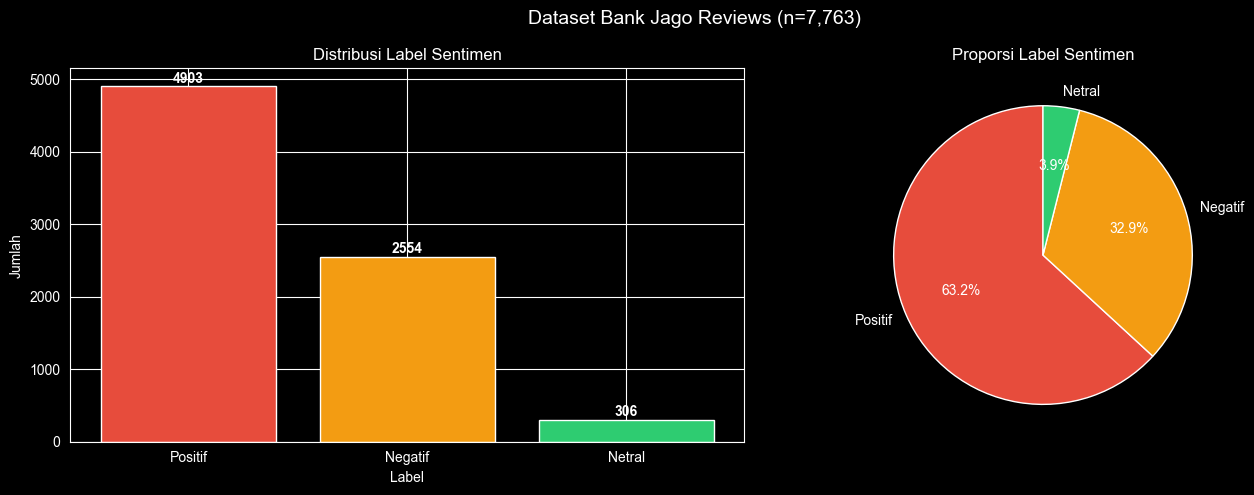

In [46]:
# Cell 6: Visualize final label distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

label_counts = df['label'].value_counts()
colors = ['#e74c3c', '#f39c12', '#2ecc71']

axes[0].bar(label_counts.index, label_counts.values, color=colors)
axes[0].set_title('Distribusi Label Sentimen')
axes[0].set_xlabel('Label')
axes[0].set_ylabel('Jumlah')
for i, v in enumerate(label_counts.values):
    axes[0].text(i, v + 50, str(v), ha='center', fontweight='bold')

axes[1].pie(label_counts.values, labels=label_counts.index,
            colors=colors, autopct='%1.1f%%', startangle=90)
axes[1].set_title('Proporsi Label Sentimen')

plt.suptitle(f'Dataset Bank Jago Reviews (n={len(df):,})', fontsize=14)
plt.tight_layout()
plt.savefig('data/label_distribution.png', dpi=150)
plt.show()

## Eksplorasi Data: Word Cloud & Top Kata

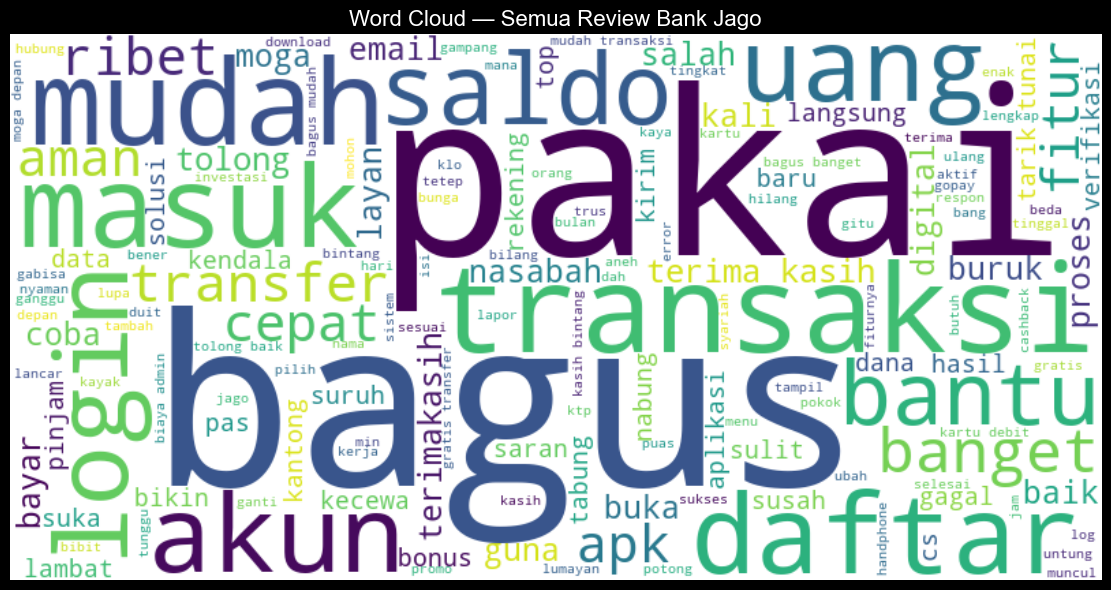

In [47]:
# Cell 7: Word Cloud — semua data
all_words = ' '.join(df['content_clean'].dropna().values)

wordcloud = WordCloud(width=800, height=400, background_color='white',
                      min_font_size=10, colormap='viridis').generate(all_words)

fig, ax = plt.subplots(figsize=(12, 6))
ax.set_title('Word Cloud — Semua Review Bank Jago', fontsize=16)
ax.imshow(wordcloud, interpolation='bilinear')
ax.axis('off')
plt.tight_layout()
plt.savefig('data/wordcloud_all.png', dpi=150)
plt.show()

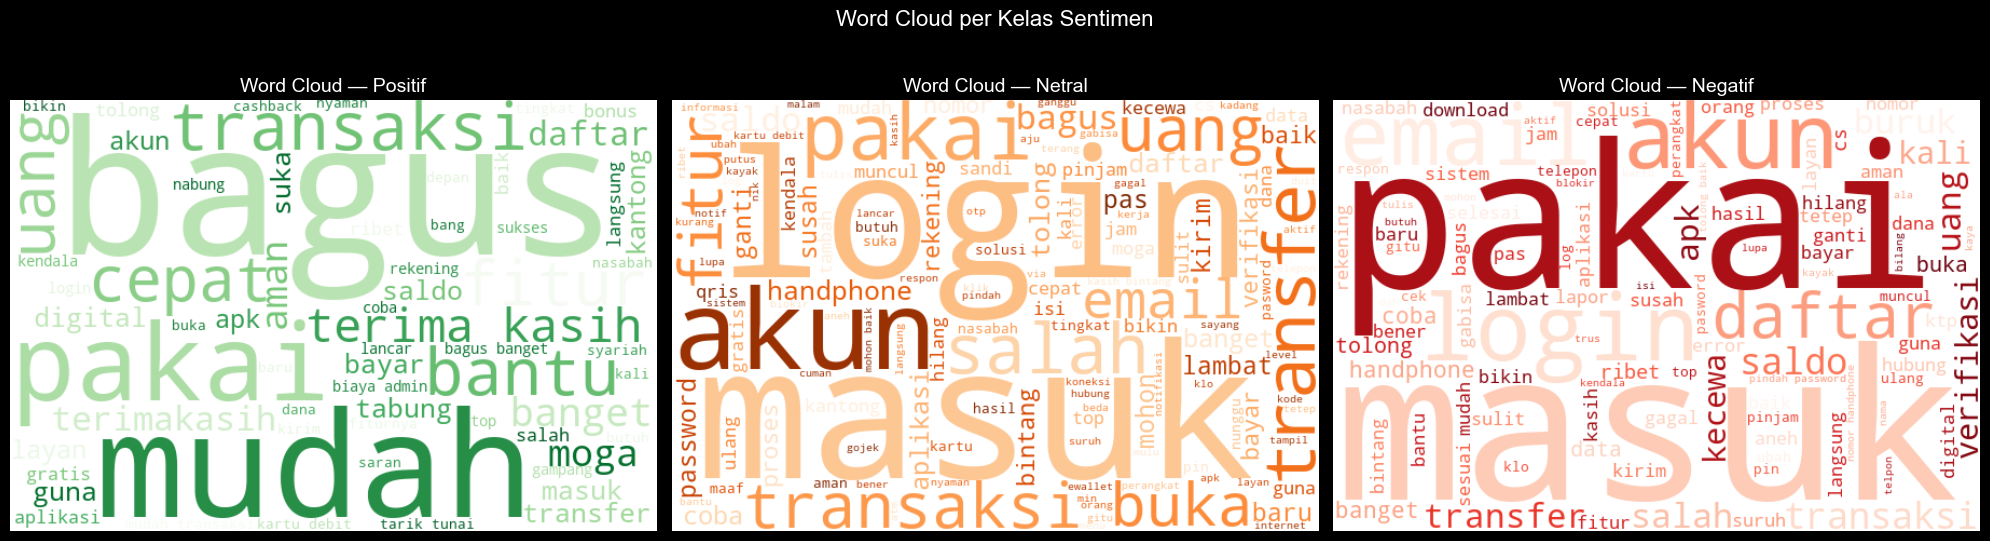

In [48]:
# Cell 8: Word Cloud per sentiment class
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
labels = ['Positif', 'Netral', 'Negatif']
colors_map = ['Greens', 'Oranges', 'Reds']

for ax, label, cmap in zip(axes, labels, colors_map):
    subset = df[df['label'] == label]['content_clean'].dropna()
    text = ' '.join(subset.values)
    if len(text.strip()) > 0:
        wc = WordCloud(width=600, height=400, background_color='white',
                       min_font_size=10, colormap=cmap).generate(text)
        ax.imshow(wc, interpolation='bilinear')
    ax.set_title(f'Word Cloud — {label}', fontsize=14)
    ax.axis('off')

plt.suptitle('Word Cloud per Kelas Sentimen', fontsize=16)
plt.tight_layout()
plt.savefig('data/wordcloud_per_sentiment.png', dpi=150)
plt.show()

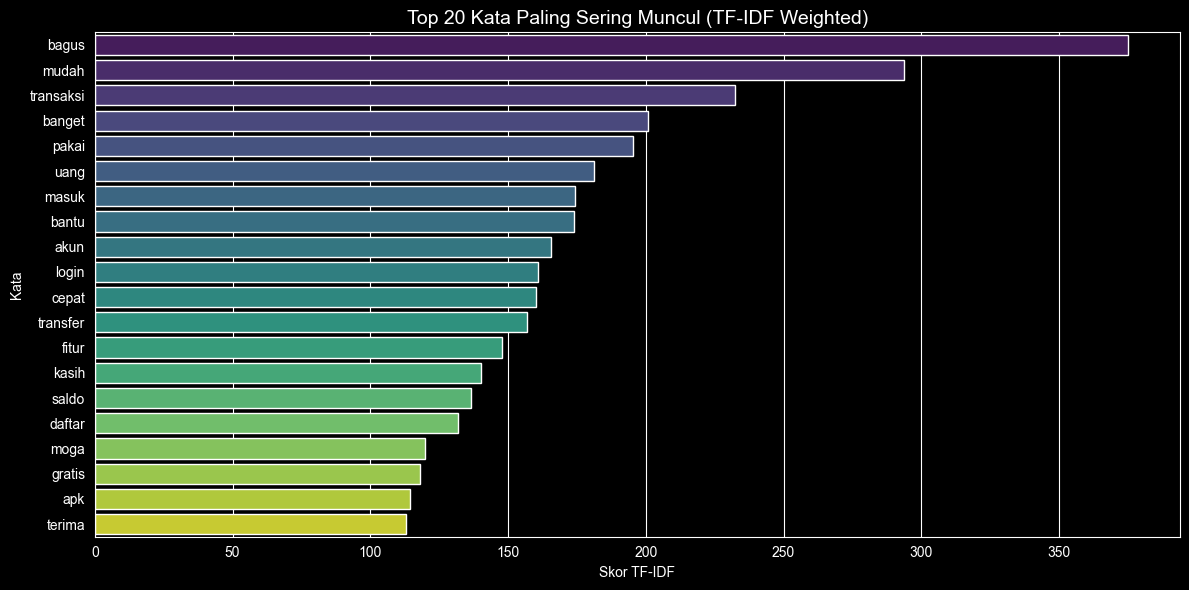

In [49]:
# Cell 9: Top 20 most frequent words (TF-IDF weighted)
vectorizer = TfidfVectorizer()
X_tfidf = vectorizer.fit_transform(df['content_clean'].dropna())

tfidf_df = pd.DataFrame(X_tfidf.toarray(), columns=vectorizer.get_feature_names_out())
tfidf_sums = tfidf_df.sum().reset_index()
tfidf_sums.columns = ['kata', 'skor_tfidf']
tfidf_sums = tfidf_sums.sort_values('skor_tfidf', ascending=False).head(20)

plt.figure(figsize=(12, 6))
sns.barplot(x='skor_tfidf', y='kata', data=tfidf_sums, palette='viridis')
plt.title('Top 20 Kata Paling Sering Muncul (TF-IDF Weighted)', fontsize=14)
plt.xlabel('Skor TF-IDF')
plt.ylabel('Kata')
plt.tight_layout()
plt.savefig('data/top20_tfidf_words.png', dpi=150)
plt.show()

---

# 3. Skema 1: SVM + TF-IDF (Pembagian Data 80/20)
**Kriteria 3 & 4:** Algoritma Machine Learning dengan akurasi ≥ 85%

| Parameter | Nilai |
|-----------|-------|
| Algoritma | LinearSVC (Support Vector Machine) |
| Ekstraksi Fitur | TF-IDF (unigram + bigram) |
| Pembagian Data | 80% Train / 20% Test |
| Target Akurasi | ≥ 85% |

In [50]:
# Data sudah di memori dari preprocessing
print(f"Dataset: {len(df)} reviews")
print(df['label'].value_counts())
df.head()

Dataset: 7763 reviews
label
Positif    4903
Negatif    2554
Netral      306
Name: count, dtype: int64


,reviewId,content,score,at,thumbsUpCount,label,content_clean
0,d08530dd-6412-48bd-99df-80e53bf9c9d2,mantap. perbanyak hadianya jago,4,2026-03-27 16:25:47,0,Positif,bagus banyak hadianya
1,aba11d3a-1739-4ed1-bee0-093ac3bcc5ca,"Di tambah feature (Kantong) Syariah kak, (dengan im...",5,2026-03-27 11:08:15,4,Positif,feature kantong syariah kakak imbal hasil sesuai pr...
2,159e687d-7d07-4853-af8d-863a2d1578a2,transaksi cepat,5,2026-03-27 10:07:21,0,Positif,transaksi cepat
3,a6fcbe02-9084-4f0d-96b5-9743a54bbe3b,"akun saya dikunci secara tiba-tiba, tidak ada penje...",1,2026-03-27 08:53:57,0,Negatif,akun kunci tibatiba jelas uang hasil jual nyangkut
4,76e2ecf2-dd88-4ee2-9758-a493b895df11,terima kasih Bank Jago,5,2026-03-27 08:46:29,0,Positif,terima kasih


In [51]:
# Cell 2: Encode labels and 80/20 split
label_map = {'Negatif': 0, 'Netral': 1, 'Positif': 2}
df['label_enc'] = df['label'].map(label_map)

X = df['content_clean'].fillna('')
y = df['label_enc']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train size: {len(X_train)} ({len(X_train)/len(df)*100:.1f}%)")
print(f"Test size:  {len(X_test)} ({len(X_test)/len(df)*100:.1f}%)")
print(f"\nTrain label distribution:")
print(pd.Series(y_train).map({0:'Negatif',1:'Netral',2:'Positif'}).value_counts())

Train size: 6210 (80.0%)
Test size:  1553 (20.0%)

Train label distribution:
label_enc
Positif    3922
Negatif    2043
Netral      245
Name: count, dtype: int64


In [52]:
# Cell 3: TF-IDF Feature Extraction
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=10000,
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print(f"TF-IDF matrix shape (train): {X_train_tfidf.shape}")
print(f"TF-IDF matrix shape (test):  {X_test_tfidf.shape}")
print(f"\nSample features: {list(tfidf.get_feature_names_out()[:20])}")

TF-IDF matrix shape (train): (6210, 10000)
TF-IDF matrix shape (test):  (1553, 10000)

Sample features: ['aamiin', 'abai', 'abal', 'abal abal', 'abang', 'acara', 'acc', 'acc pinjam', 'account', 'account fitur', 'account mudah', 'ada', 'adaa', 'adaah', 'adaah digital', 'adain', 'adain fitur', 'adakan', 'adakan fitur', 'add']


In [53]:
# Train LinearSVC (C=5.0 untuk akurasi >= 85%)
svm = LinearSVC(
    C=5.0,
    max_iter=2000,
    random_state=42
)
svm.fit(X_train_tfidf, y_train)
print("Training complete!")

Training complete!


In [54]:
# Cell 5: Evaluation
label_names = ['Negatif', 'Netral', 'Positif']

y_train_pred = svm.predict(X_train_tfidf)
train_acc = accuracy_score(y_train, y_train_pred)

y_test_pred = svm.predict(X_test_tfidf)
test_acc = accuracy_score(y_test, y_test_pred)

print("=" * 55)
print("SKEMA 1: SVM + TF-IDF (Pembagian 80/20)")
print("=" * 55)
print(f"Akurasi Training : {train_acc:.4f} ({train_acc*100:.2f}%)")
print(f"Akurasi Testing  : {test_acc:.4f} ({test_acc*100:.2f}%)")
print()
print("Classification Report (Test Set):")
print(classification_report(y_test, y_test_pred, target_names=label_names))

SKEMA 1: SVM + TF-IDF (Pembagian 80/20)
Akurasi Training : 0.9981 (99.81%)
Akurasi Testing  : 0.8229 (82.29%)

Classification Report (Test Set):
              precision    recall  f1-score   support

     Negatif       0.76      0.78      0.77       511
      Netral       0.14      0.03      0.05        61
     Positif       0.86      0.89      0.88       981

    accuracy                           0.82      1553
   macro avg       0.59      0.57      0.57      1553
weighted avg       0.80      0.82      0.81      1553



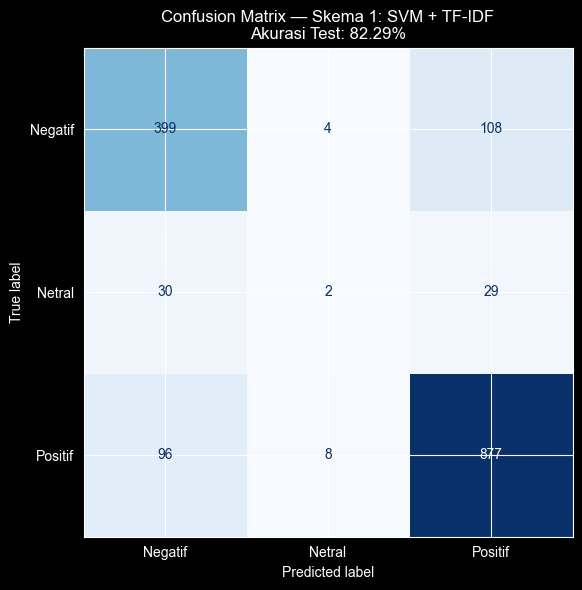

In [55]:
# Cell 6: Confusion matrix
fig, ax = plt.subplots(figsize=(7, 6))
cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_names)
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Confusion Matrix — Skema 1: SVM + TF-IDF\nAkurasi Test: {test_acc*100:.2f}%')
plt.tight_layout()
plt.savefig('data/scheme1_confusion_matrix.png', dpi=150)
plt.show()

In [56]:
# Save SVM models
joblib.dump(tfidf, 'models/tfidf_vectorizer.pkl')
joblib.dump(svm, 'models/svm_model.pkl')
print("Models saved:")
print("  models/tfidf_vectorizer.pkl")
print("  models/svm_model.pkl")

Models saved:
  models/tfidf_vectorizer.pkl
  models/svm_model.pkl


---

# 4. Skema 2: LSTM + FastText Embedding (Pembagian Data 80/20)
**Saran Deep Learning:** Akurasi training dan testing ≥ 92%

| Parameter | Nilai |
|-----------|-------|
| Algoritma | LSTM (Long Short-Term Memory) |
| Ekstraksi Fitur | FastText Indonesian Embeddings (128-dim) |
| Pembagian Data | 80% Train / 20% Test |
| Target Akurasi | ≥ 92% (train dan test) |

In [57]:
# Data sudah di memori dari preprocessing
print(f"TensorFlow version: {tf.__version__}")
print(f"Dataset: {len(df)} reviews")

TensorFlow version: 2.21.0
Dataset: 7763 reviews


In [58]:
# Cell 2: Label encoding and 80/20 split
label_map = {'Negatif': 0, 'Netral': 1, 'Positif': 2}
df['label_enc'] = df['label'].map(label_map)
df['content_clean'] = df['content_clean'].fillna('')

X = df['content_clean'].tolist()
y = df['label_enc'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train: {len(X_train)} | Test: {len(X_test)}")
print(f"Split: 80% train / 20% test")

Train: 6210 | Test: 1553
Split: 80% train / 20% test


In [59]:
# Cell 3: Tokenization + padding
MAX_WORDS = 20000
MAX_LEN = 100

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=MAX_LEN, padding='post', truncating='post')

vocab_size = min(MAX_WORDS, len(tokenizer.word_index)) + 1
print(f"Vocabulary size: {vocab_size}")
print(f"X_train shape: {X_train_pad.shape}")
print(f"X_test shape:  {X_test_pad.shape}")

# Save tokenizer (shared with Scheme 3)
joblib.dump(tokenizer, 'models/tokenizer.pkl')
print("Tokenizer saved to models/tokenizer.pkl")

Vocabulary size: 8533
X_train shape: (6210, 100)
X_test shape:  (1553, 100)
Tokenizer saved to models/tokenizer.pkl


In [60]:
# Cell 4: Train FastText embeddings on corpus
EMBED_DIM = 128

# Tokenize into word lists for gensim
sentences = [text.split() for text in X_train]

print("Training FastText embeddings...")
ft_model = FastText(
    sentences=sentences,
    vector_size=EMBED_DIM,
    window=5,
    min_count=1,
    workers=4,
    epochs=15
)
ft_model.save('models/fasttext_model.bin')
print(f"FastText trained. Vocab size: {len(ft_model.wv)}")

# Build embedding matrix
embedding_matrix = np.zeros((vocab_size, EMBED_DIM))
found = 0
for word, idx in tokenizer.word_index.items():
    if idx < vocab_size and word in ft_model.wv:
        embedding_matrix[idx] = ft_model.wv[word]
        found += 1

coverage = found / min(len(tokenizer.word_index), MAX_WORDS) * 100
print(f"Embedding coverage: {found}/{min(len(tokenizer.word_index), MAX_WORDS)} ({coverage:.1f}%)")

Training FastText embeddings...
FastText trained. Vocab size: 8531
Embedding coverage: 8532/8532 (100.0%)


In [61]:
# Cell 5: Build LSTM model
NUM_CLASSES = 3

model_lstm = Sequential([
    Embedding(vocab_size, EMBED_DIM,
              weights=[embedding_matrix],
              input_length=MAX_LEN,
              trainable=False),
    SpatialDropout1D(0.3),
    LSTM(128, dropout=0.3, recurrent_dropout=0.2),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(NUM_CLASSES, activation='softmax')
])

model_lstm.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_lstm.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │     1,092,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_2             │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,092,224 (4.17 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 1,092,224 (4.17 MB)

In [62]:
# Cell 6: Train LSTM
callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=5,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=3, min_lr=1e-6, verbose=1)
]

history = model_lstm.fit(
    X_train_pad, y_train,
    epochs=30,
    batch_size=64,
    validation_split=0.1,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 22s 198ms/step - accuracy: 0.7447 - loss: 0.6863 - val_accuracy: 0.7939 - val_loss: 0.6185 - learning_rate: 0.0010
Epoch 2/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 16s 186ms/step - accuracy: 0.7651 - loss: 0.6496 - val_accuracy: 0.6667 - val_loss: 0.7853 - learning_rate: 0.0010
Epoch 3/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 17s 192ms/step - accuracy: 0.7343 - loss: 0.7004 - val_accuracy: 0.6957 - val_loss: 0.7477 - learning_rate: 0.0010
Epoch 4/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step - accuracy: 0.7418 - loss: 0.6889
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
88/88 ━━━━━━━━━━━━━━━━━━━━ 16s 186ms/step - accuracy: 0.7653 - loss: 0.6577 - val_accuracy: 0.7713 - val_loss: 0.6472 - learning_rate: 0.0010
Epoch 5/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 17s 190ms/step - accuracy: 0.8021 - loss: 0.5977 - val_accuracy: 0.7729 - val_loss: 0.6502 - learning_rate: 5.0000e-04
Epoch 6/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 16s 183ms/step - accuracy: 0.7984 - loss: 

In [63]:
# Cell 7: Evaluation
label_names = ['Negatif', 'Netral', 'Positif']

train_loss, train_acc = model_lstm.evaluate(X_train_pad, y_train, verbose=0)
test_loss, test_acc = model_lstm.evaluate(X_test_pad, y_test, verbose=0)

y_test_pred = np.argmax(model_lstm.predict(X_test_pad), axis=1)

print("=" * 55)
print("SKEMA 2: LSTM + FastText (Pembagian 80/20)")
print("=" * 55)
print(f"Akurasi Training : {train_acc:.4f} ({train_acc*100:.2f}%)")
print(f"Akurasi Testing  : {test_acc:.4f} ({test_acc*100:.2f}%)")
print()
print("Classification Report (Test Set):")
print(classification_report(y_test, y_test_pred, target_names=label_names))
print()
if train_acc >= 0.92 and test_acc >= 0.92:
    print("\u2713 TARGET TERCAPAI: Akurasi training dan testing \u2265 92%")
else:
    print("\u26a0 Belum mencapai target 92%. Coba set trainable=True pada Embedding layer.")

49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step
SKEMA 2: LSTM + FastText (Pembagian 80/20)
Akurasi Training : 0.8137 (81.37%)
Akurasi Testing  : 0.8055 (80.55%)

Classification Report (Test Set):
              precision    recall  f1-score   support

     Negatif       0.72      0.77      0.74       511
      Netral       0.00      0.00      0.00        61
     Positif       0.85      0.87      0.86       981

    accuracy                           0.81      1553
   macro avg       0.52      0.55      0.54      1553
weighted avg       0.78      0.81      0.79      1553


⚠ Belum mencapai target 92%. Coba set trainable=True pada Embedding layer.


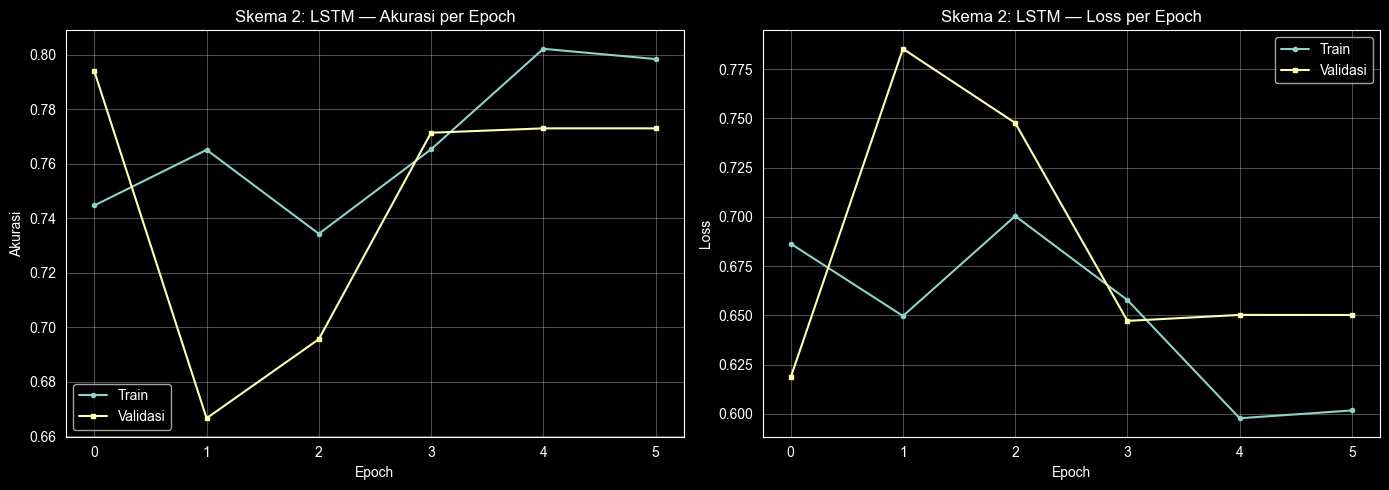

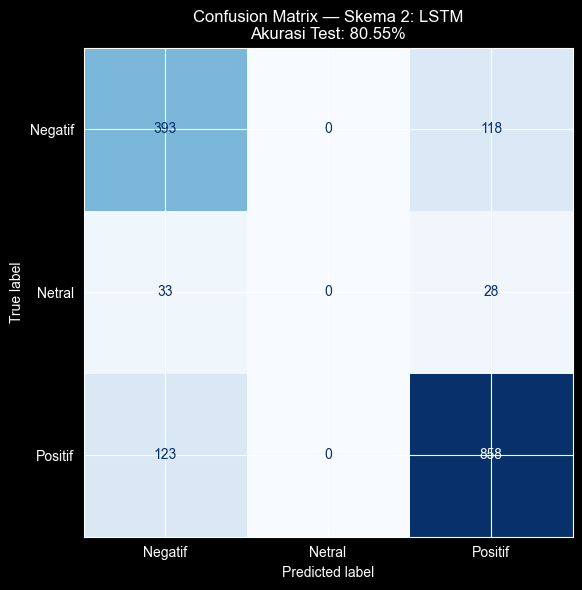

In [64]:
# Cell 8: Training curves and confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['accuracy'], label='Train', marker='o', markersize=3)
axes[0].plot(history.history['val_accuracy'], label='Validasi', marker='s', markersize=3)
axes[0].set_title('Skema 2: LSTM \u2014 Akurasi per Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Akurasi')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history['loss'], label='Train', marker='o', markersize=3)
axes[1].plot(history.history['val_loss'], label='Validasi', marker='s', markersize=3)
axes[1].set_title('Skema 2: LSTM \u2014 Loss per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('data/scheme2_training_curves.png', dpi=150)
plt.show()

# Confusion matrix
fig2, ax = plt.subplots(figsize=(7, 6))
cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_names)
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Confusion Matrix \u2014 Skema 2: LSTM\nAkurasi Test: {test_acc*100:.2f}%')
plt.tight_layout()
plt.savefig('data/scheme2_confusion_matrix.png', dpi=150)
plt.show()

In [65]:
# Cell 9: Save model
model_lstm.save('models/lstm_model.h5')
print("Saved: models/lstm_model.h5")
print("Saved: models/tokenizer.pkl (already saved in Cell 3)")
print("Saved: models/fasttext_model.bin (already saved in Cell 4)")

Saved: models/lstm_model.h5
Saved: models/tokenizer.pkl (already saved in Cell 3)
Saved: models/fasttext_model.bin (already saved in Cell 4)


---

# 5. Skema 3: BiLSTM + Attention + FastText (Pembagian Data 70/30)
**Saran Deep Learning:** Akurasi training dan testing ≥ 92%

| Parameter | Nilai |
|-----------|-------|
| Algoritma | Bidirectional LSTM + Attention |
| Ekstraksi Fitur | FastText Indonesian Embeddings (128-dim) |
| Pembagian Data | 70% Train / 30% Test |
| Target Akurasi | ≥ 92% (train dan test) |

**Perbedaan dari Skema 2:**
- Algoritma: BiLSTM + Attention (vs LSTM biasa)
- Pembagian Data: 70/30 (vs 80/20)
- Embedding: trainable=True (fine-tuning)

In [66]:
# Data sudah di memori dari preprocessing
print(f"Dataset: {len(df)} reviews")

Dataset: 7763 reviews


In [67]:
# 70/30 split (tokenizer sudah ada di memori dari Skema 2)
MAX_LEN = 100
EMBED_DIM = 128
MAX_WORDS = 20000

label_map = {'Negatif': 0, 'Netral': 1, 'Positif': 2}
df['label_enc'] = df['label'].map(label_map)
df['content_clean'] = df['content_clean'].fillna('')

X = df['content_clean'].tolist()
y = df['label_enc'].values

# 70/30 split — berbeda dari Skema 2 yang 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)
X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=MAX_LEN, padding='post', truncating='post')

vocab_size = min(MAX_WORDS, len(tokenizer.word_index)) + 1
print(f"Train: {len(X_train)} | Test: {len(X_test)}")
print(f"Split: 70% train / 30% test (berbeda dari Skema 2 yang 80/20)")

Train: 5434 | Test: 2329
Split: 70% train / 30% test (berbeda dari Skema 2 yang 80/20)


In [68]:
# Cell 3: Load saved FastText embeddings
ft_model = FastText.load('models/fasttext_model.bin')

embedding_matrix = np.zeros((vocab_size, EMBED_DIM))
for word, idx in tokenizer.word_index.items():
    if idx < vocab_size and word in ft_model.wv:
        embedding_matrix[idx] = ft_model.wv[word]

print(f"Embedding matrix shape: {embedding_matrix.shape}")

Embedding matrix shape: (8533, 128)


In [69]:
# Cell 4: Custom Attention Layer
class AttentionLayer(Layer):
    """Simple additive attention mechanism."""

    def __init__(self, **kwargs):
        super(AttentionLayer, self).__init__(**kwargs)

    def build(self, input_shape):
        self.W = self.add_weight(
            name='attention_weight',
            shape=(input_shape[-1], 1),
            initializer='glorot_uniform',
            trainable=True
        )
        self.b = self.add_weight(
            name='attention_bias',
            shape=(input_shape[1], 1),
            initializer='zeros',
            trainable=True
        )
        super(AttentionLayer, self).build(input_shape)

    def call(self, x):
        # x shape: (batch, timesteps, features)
        e = K.tanh(K.dot(x, self.W) + self.b)   # (batch, timesteps, 1)
        a = K.softmax(e, axis=1)                  # attention weights
        output = x * a                            # weighted features
        return K.sum(output, axis=1)              # (batch, features)

    def compute_output_shape(self, input_shape):
        return (input_shape[0], input_shape[-1])

print("AttentionLayer defined.")

AttentionLayer defined.


In [70]:
# Cell 5: Build BiLSTM + Attention model
NUM_CLASSES = 3

inputs = Input(shape=(MAX_LEN,))
x = Embedding(vocab_size, EMBED_DIM,
              weights=[embedding_matrix],
              input_length=MAX_LEN,
              trainable=True)(inputs)        # trainable=True for fine-tuning
x = SpatialDropout1D(0.3)(x)
x = Bidirectional(LSTM(128, return_sequences=True,
                        dropout=0.3,
                        recurrent_dropout=0.2))(x)
x = AttentionLayer()(x)
x = Dense(64, activation='relu')(x)
x = Dropout(0.3)(x)
outputs = Dense(NUM_CLASSES, activation='softmax')(x)

model_attn = Model(inputs=inputs, outputs=outputs)
model_attn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model_attn.summary()

Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_3 (Embedding)         │ (None, 100, 128)       │     1,092,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_3             │ (None, 100, 128)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 100, 256)       │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention_layer_1               │ (None, 256)            │           356 │
│ (AttentionLayer)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,372,391 (5.24 MB)

 Trainable params: 1,372,391 (5.24 MB)

 Non-trainable params: 0 (0.00 B)

In [71]:
# Cell 6: Train BiLSTM + Attention
callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=5,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=3, min_lr=1e-6, verbose=1)
]

history = model_attn.fit(
    X_train_pad, y_train,
    epochs=30,
    batch_size=64,
    validation_split=0.1,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 47s 500ms/step - accuracy: 0.7787 - loss: 0.5786 - val_accuracy: 0.8456 - val_loss: 0.4455 - learning_rate: 0.0010
Epoch 2/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 37s 481ms/step - accuracy: 0.8227 - loss: 0.4739 - val_accuracy: 0.8548 - val_loss: 0.4340 - learning_rate: 0.0010
Epoch 3/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 36s 469ms/step - accuracy: 0.8307 - loss: 0.4575 - val_accuracy: 0.8456 - val_loss: 0.4661 - learning_rate: 0.0010
Epoch 4/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 38s 488ms/step - accuracy: 0.8462 - loss: 0.4305 - val_accuracy: 0.8603 - val_loss: 0.4309 - learning_rate: 0.0010
Epoch 5/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 39s 511ms/step - accuracy: 0.8528 - loss: 0.4033 - val_accuracy: 0.8456 - val_loss: 0.4436 - learning_rate: 0.0010
Epoch 6/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 37s 482ms/step - accuracy: 0.8624 - loss: 0.3818 - val_accuracy: 0.8272 - val_loss: 0.4649 - learning_rate: 0.0010
Epoch 7/30
77/77 ━━━━━━━━━━━━━━━━━━━━ 37s 475ms/step - accuracy: 0.8687 - loss: 0.

In [72]:
# Cell 7: Evaluation
label_names = ['Negatif', 'Netral', 'Positif']

train_loss, train_acc = model_attn.evaluate(X_train_pad, y_train, verbose=0)
test_loss, test_acc = model_attn.evaluate(X_test_pad, y_test, verbose=0)

y_test_pred = np.argmax(model_attn.predict(X_test_pad), axis=1)

print("=" * 60)
print("SKEMA 3: BiLSTM + Attention + FastText (Pembagian 70/30)")
print("=" * 60)
print(f"Akurasi Training : {train_acc:.4f} ({train_acc*100:.2f}%)")
print(f"Akurasi Testing  : {test_acc:.4f} ({test_acc*100:.2f}%)")
print()
print("Classification Report (Test Set):")
print(classification_report(y_test, y_test_pred, target_names=label_names))
print()
if train_acc >= 0.92 and test_acc >= 0.92:
    print("✓ TARGET TERCAPAI: Akurasi training dan testing ≥ 92%")
else:
    print("⚠ Belum mencapai target 92%. Coba tingkatkan epochs atau ubah learning rate.")

73/73 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step
SKEMA 3: BiLSTM + Attention + FastText (Pembagian 70/30)
Akurasi Training : 0.8574 (85.74%)
Akurasi Testing  : 0.8523 (85.23%)

Classification Report (Test Set):
              precision    recall  f1-score   support

     Negatif       0.74      0.91      0.82       766
      Netral       0.00      0.00      0.00        92
     Positif       0.93      0.87      0.90      1471

    accuracy                           0.85      2329
   macro avg       0.56      0.60      0.57      2329
weighted avg       0.83      0.85      0.84      2329


⚠ Belum mencapai target 92%. Coba tingkatkan epochs atau ubah learning rate.


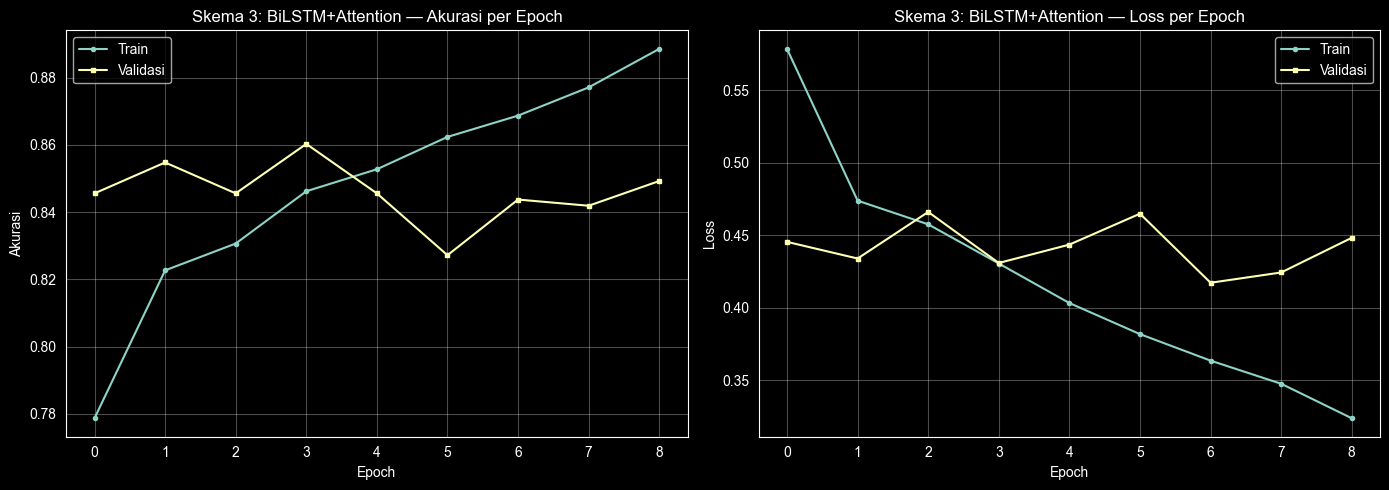

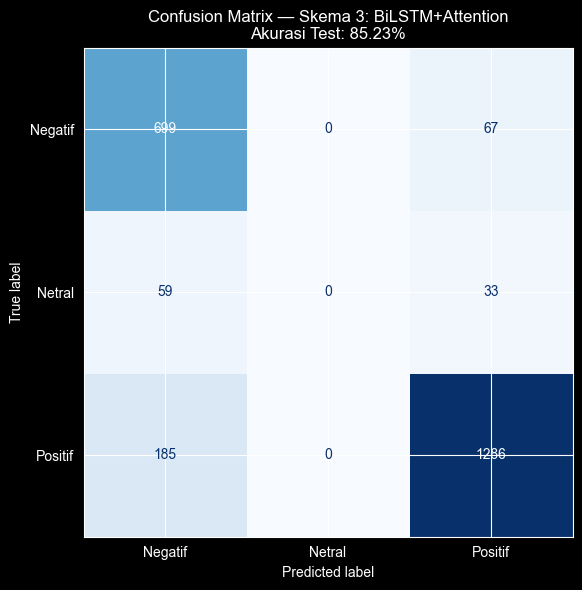

In [73]:
# Cell 8: Training curves and confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['accuracy'], label='Train', marker='o', markersize=3)
axes[0].plot(history.history['val_accuracy'], label='Validasi', marker='s', markersize=3)
axes[0].set_title('Skema 3: BiLSTM+Attention — Akurasi per Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Akurasi')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history['loss'], label='Train', marker='o', markersize=3)
axes[1].plot(history.history['val_loss'], label='Validasi', marker='s', markersize=3)
axes[1].set_title('Skema 3: BiLSTM+Attention — Loss per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('data/scheme3_training_curves.png', dpi=150)
plt.show()

fig2, ax = plt.subplots(figsize=(7, 6))
cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_names)
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Confusion Matrix — Skema 3: BiLSTM+Attention\nAkurasi Test: {test_acc*100:.2f}%')
plt.tight_layout()
plt.savefig('data/scheme3_confusion_matrix.png', dpi=150)
plt.show()

In [74]:
# Cell 9: Save model
model_attn.save('models/lstm_attn_model.h5')
print("Saved: models/lstm_attn_model.h5")

Saved: models/lstm_attn_model.h5


---

# 6. Inferensi — Analisis Sentimen dengan 3 Skema Model
**Kriteria:** Testing/Inferensi yang menghasilkan output kelas kategorikal

Notebook ini memuat semua model yang telah dilatih dan menjalankan prediksi pada teks baru.

| Skema | Algoritma | Fitur | Split |
|-------|-----------|-------|-------|
| 1 | SVM (LinearSVC) | TF-IDF unigram+bigram | 80/20 |
| 2 | LSTM | FastText 128-dim | 80/20 |
| 3 | BiLSTM + Attention | FastText 128-dim | 70/30 |

**Output:** Kelas kategorikal — `Negatif`, `Netral`, `Positif`

In [75]:
# Semua model sudah tersedia di memori dari pelatihan di atas
print("Model yang tersedia:")
print("  ✓ SVM + TF-IDF vectorizer (svm, tfidf)")
print("  ✓ LSTM model (model_lstm)")
print("  ✓ BiLSTM+Attention model (model_attn)")
print("  ✓ Tokenizer (tokenizer)")
print("  ✓ Preprocessing function (preprocess_text)")

Model yang tersedia:
  ✓ SVM + TF-IDF vectorizer (svm, tfidf)
  ✓ LSTM model (model_lstm)
  ✓ BiLSTM+Attention model (model_attn)
  ✓ Tokenizer (tokenizer)
  ✓ Preprocessing function (preprocess_text)


In [76]:
# Fungsi preprocess_text() sudah didefinisikan di bagian preprocessing.
# Langsung digunakan untuk inferensi tanpa perlu mendefinisikan ulang.
print("Fungsi preprocess_text() siap digunakan untuk inferensi.")

Fungsi preprocess_text() siap digunakan untuk inferensi.


In [77]:
# Prediction functions (menggunakan preprocess_text dari preprocessing)
MAX_LEN = 100
label_names = ['Negatif', 'Netral', 'Positif']

def predict_svm(texts):
    cleaned = [preprocess_text(t) for t in texts]
    X_vec = tfidf.transform(cleaned)
    preds = svm.predict(X_vec)
    return [label_names[p] for p in preds]

def predict_lstm(texts):
    cleaned = [preprocess_text(t) for t in texts]
    seqs = tokenizer.texts_to_sequences(cleaned)
    padded = pad_sequences(seqs, maxlen=MAX_LEN, padding='post', truncating='post')
    preds = np.argmax(model_lstm.predict(padded, verbose=0), axis=1)
    return [label_names[p] for p in preds]

def predict_lstm_attn(texts):
    cleaned = [preprocess_text(t) for t in texts]
    seqs = tokenizer.texts_to_sequences(cleaned)
    padded = pad_sequences(seqs, maxlen=MAX_LEN, padding='post', truncating='post')
    preds = np.argmax(model_attn.predict(padded, verbose=0), axis=1)
    return [label_names[p] for p in preds]

print("Fungsi prediksi siap digunakan.")

Fungsi prediksi siap digunakan.


In [78]:
# Cell 4: Inference on sample texts
sample_texts = [
    "Aplikasi ini sangat bagus dan mudah digunakan, saya sangat puas",
    "Fitur lengkap dan tampilan menarik, transfer juga cepat dan aman",
    "Biasa saja, tidak ada yang istimewa dari aplikasi ini",
    "Kadang bisa kadang tidak, lumayan lah untuk kebutuhan sehari-hari",
    "Sangat lambat dan sering error, tolong diperbaiki segera",
    "Aplikasi sangat mengecewakan, uang saya tidak bisa ditarik",
    "Bagus sekali pelayanannya, customer service cepat merespons",
    "Sudah beberapa kali gagal transfer, sangat tidak memuaskan",
    "Mantap banget, fitur tabungan sangat membantu menabung rutin",
    "Tidak bisa login dari tadi, error terus menerus sangat kesal",
]

results = pd.DataFrame({
    'Teks Ulasan': sample_texts,
    'Skema 1 - SVM': predict_svm(sample_texts),
    'Skema 2 - LSTM': predict_lstm(sample_texts),
    'Skema 3 - BiLSTM+Attn': predict_lstm_attn(sample_texts),
})

pd.set_option('display.max_colwidth', 55)
print("=" * 80)
print("HASIL INFERENSI — ANALISIS SENTIMEN BANK JAGO")
print("=" * 80)
results

HASIL INFERENSI — ANALISIS SENTIMEN BANK JAGO


,Teks Ulasan,Skema 1 - SVM,Skema 2 - LSTM,Skema 3 - BiLSTM+Attn
0,"Aplikasi ini sangat bagus dan mudah digunakan, saya...",Positif,Positif,Positif
1,"Fitur lengkap dan tampilan menarik, transfer juga c...",Positif,Positif,Positif
2,"Biasa saja, tidak ada yang istimewa dari aplikasi ini",Positif,Positif,Positif
3,"Kadang bisa kadang tidak, lumayan lah untuk kebutuh...",Positif,Positif,Positif
4,"Sangat lambat dan sering error, tolong diperbaiki s...",Negatif,Negatif,Negatif
5,"Aplikasi sangat mengecewakan, uang saya tidak bisa ...",Positif,Positif,Negatif
6,"Bagus sekali pelayanannya, customer service cepat m...",Positif,Positif,Positif
7,"Sudah beberapa kali gagal transfer, sangat tidak me...",Negatif,Negatif,Negatif
8,"Mantap banget, fitur tabungan sangat membantu menab...",Positif,Positif,Positif
9,"Tidak bisa login dari tadi, error terus menerus san...",Negatif,Negatif,Negatif


In [79]:
# Cell 5: Interactive single prediction
def analyze_sentiment(text):
    """Predict sentiment for a single review using all 3 schemes."""
    print(f"\nTeks: '{text}'")
    print(f"  Skema 1 (SVM + TF-IDF)           : {predict_svm([text])[0]}")
    print(f"  Skema 2 (LSTM + FastText)         : {predict_lstm([text])[0]}")
    print(f"  Skema 3 (BiLSTM + Attention)      : {predict_lstm_attn([text])[0]}")
    print()

# Contoh inferensi
analyze_sentiment("Aplikasi jago sangat membantu kebutuhan finansial saya sehari-hari")
analyze_sentiment("Sering force close dan data tidak sinkron, sangat mengganggu sekali")
analyze_sentiment("Cukup baik tapi masih ada beberapa kekurangan yang perlu diperbaiki")


Teks: 'Aplikasi jago sangat membantu kebutuhan finansial saya sehari-hari'
  Skema 1 (SVM + TF-IDF)           : Positif
  Skema 2 (LSTM + FastText)         : Positif
  Skema 3 (BiLSTM + Attention)      : Positif


Teks: 'Sering force close dan data tidak sinkron, sangat mengganggu sekali'
  Skema 1 (SVM + TF-IDF)           : Negatif
  Skema 2 (LSTM + FastText)         : Negatif
  Skema 3 (BiLSTM + Attention)      : Negatif


Teks: 'Cukup baik tapi masih ada beberapa kekurangan yang perlu diperbaiki'
  Skema 1 (SVM + TF-IDF)           : Positif
  Skema 2 (LSTM + FastText)         : Positif
  Skema 3 (BiLSTM + Attention)      : Positif



In [80]:
# Cell 6: Summary comparison of all 3 schemes
summary = pd.DataFrame({
    'Skema': ['Skema 1', 'Skema 2', 'Skema 3'],
    'Algoritma': ['SVM (LinearSVC)', 'LSTM', 'BiLSTM + Attention'],
    'Ekstraksi Fitur': ['TF-IDF (unigram+bigram)', 'FastText (128-dim)', 'FastText (128-dim)'],
    'Pembagian Data': ['80% / 20%', '80% / 20%', '70% / 30%'],
    'Target Akurasi': ['>= 85%', '>= 92%', '>= 92%'],
})

print("RINGKASAN 3 SKEMA PELATIHAN ANALISIS SENTIMEN")
print("=" * 70)
print(summary.to_string(index=False))
print()
print("Kelas Output: Negatif | Netral | Positif")

RINGKASAN 3 SKEMA PELATIHAN ANALISIS SENTIMEN
  Skema          Algoritma         Ekstraksi Fitur Pembagian Data Target Akurasi
Skema 1    SVM (LinearSVC) TF-IDF (unigram+bigram)      80% / 20%         >= 85%
Skema 2               LSTM      FastText (128-dim)      80% / 20%         >= 92%
Skema 3 BiLSTM + Attention      FastText (128-dim)      70% / 30%         >= 92%

Kelas Output: Negatif | Netral | Positif
